# Implementasi & Evaluasi Metode Multinomial Naive Bayes (MNB)

Notebook ini mengimplementasikan **Subbab 3.10 (Implementasi Multinomial Naive Bayes)** dan **Subbab 3.12 (Evaluasi Kinerja Model)** pada proposal skripsi.

### Alur Proses pada Notebook Ini:
1. **Memuat Data Latih & Data Uji Hasil TF-IDF** (`tfidf_split_data.pkl`) agar kondisi eksperimen sama persis dengan metode KNN.
2. **Melatih Model Multinomial Naive Bayes (`MultinomialNB`)** dengan *Laplace Smoothing* ($\alpha = 1.0$) serta melihat probabilitas kelas (*Prior Probability*) dan fitur terkuat.
3. **Melakukan Prediksi Sentimen pada Data Uji** beserta nilai probabilitas keyakinan model.
4. **Evaluasi Kinerja Model** menggunakan **Confusion Matrix (TP, TN, FP, FN)**, **Accuracy**, **Precision**, **Recall**, dan **F1-Score**.
5. **Menyimpan Model & Hasil Evaluasi** untuk tahap perbandingan akhir dengan K-Nearest Neighbor (KNN).

---
## 1. Import Library & Memuat Data Hasil Pembagian dan TF-IDF

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Memuat paket data hasil split (80:20) dan pembobotan TF-IDF dari tahap sebelumnya
paket_data = joblib.load("../data/tfidf_split_data.pkl")
tfidf_vectorizer = joblib.load("../data/tfidf_vectorizer.pkl")

X_train_tfidf = paket_data['X_train_tfidf']
X_test_tfidf = paket_data['X_test_tfidf']
y_train = paket_data['y_train']
y_test = paket_data['y_test']
X_train_text = paket_data['X_train_text']
X_test_text = paket_data['X_test_text']

print("=== DATA SIAP DIGUNAKAN UNTUK MULTINOMIAL NAIVE BAYES ===")
print(f"Bentuk Matriks Latih (X_train_tfidf) : {X_train_tfidf.shape[0]} dokumen x {X_train_tfidf.shape[1]} fitur")
print(f"Bentuk Matriks Uji   (X_test_tfidf)  : {X_test_tfidf.shape[0]} dokumen x {X_test_tfidf.shape[1]} fitur")
print(f"Distribusi Label Latih (y_train)     : Positif = {(y_train == 'positif').sum()}, Negatif = {(y_train == 'negatif').sum()}")
print(f"Distribusi Label Uji   (y_test)      : Positif = {(y_test == 'positif').sum()}, Negatif = {(y_test == 'negatif').sum()}")

=== DATA SIAP DIGUNAKAN UNTUK MULTINOMIAL NAIVE BAYES ===
Bentuk Matriks Latih (X_train_tfidf) : 8585 dokumen x 57901 fitur
Bentuk Matriks Uji   (X_test_tfidf)  : 2147 dokumen x 57901 fitur
Distribusi Label Latih (y_train)     : Positif = 4512, Negatif = 4073
Distribusi Label Uji   (y_test)      : Positif = 1128, Negatif = 1019


---
## 2. Pelatihan Model Multinomial Naive Bayes (`MultinomialNB`)

**Sesuai Subbab 3.10 Proposal Skripsi:**
Metode **Multinomial Naive Bayes** menghitung probabilitas suatu ulasan $D$ masuk ke dalam kelas sentimen $C$ (`positif` atau `negatif`) menggunakan **Teorema Bayes**:
$$P(C|D) = \frac{P(D|C) \cdot P(C)}{P(D)}$$

### Catatan Belajar untuk Kode di Bawah:
- **Parameter `alpha=1.0` (*Laplace Smoothing*):**
  Sesuai rumus $\theta_{yi} = \frac{N_{yi} + \alpha}{N_y + \alpha n}$ pada Bab II & III skripsi Anda, nilai `alpha=1.0` menambahkan bobot $1$ pada setiap fitur agar ketika ada kata di Data Uji yang belum pernah muncul pada kelas tertentu di Data Latih, nilai probabilitasnya **tidak menjadi nol ($0$)**.
- **Fungsi `.fit(X_train_tfidf, y_train)`:**
  Memerintahkan model untuk mempelajari dua hal dari Data Latih:
  1. **Probabilitas Awal Kelas (*Prior Probability* $P(C)$):** Proporsi awal kelas Positif dan Negatif.
  2. **Probabilitas Kondisional Fitur ($P(x_i|C)$ / *Likelihood*):** Seberapa besar kecenderungan setiap fitur Unigram/Bigram muncul pada ulasan Positif vs Negatif.

In [2]:
# 1. Inisialisasi model Multinomial Naive Bayes dengan Laplace Smoothing (alpha = 1.0)
mnb_model = MultinomialNB(alpha=1.0)

# 2. Melatih model menggunakan matriks TF-IDF Data Latih dan labelnya
mnb_model.fit(X_train_tfidf, y_train)

# Menampilkan informasi yang dipelajari oleh model dari Data Latih
kelas_model = mnb_model.classes_ # urutan kelas di dalam model (['negatif', 'positif'])
prior_prob = np.exp(mnb_model.class_log_prior_) # mengubah log prior kembali ke probabilitas asli (0 s/d 1)

print("=== MODEL MULTINOMIAL NAIVE BAYES BERHASIL DILATIH ===")
print("Parameter Smoothing (alpha) :", mnb_model.alpha)
print("\nProbabilitas Awal Kelas / Prior Probability P(C):")
for kls, prob in zip(kelas_model, prior_prob):
    print(f"  - P({kls:7s}) = {prob:.4f} ({prob * 100:.2f}%)")

# Menampilkan Top 10 fitur (Unigram/Bigram) dengan probabilitas tertinggi pada masing-masing kelas
fitur_names = tfidf_vectorizer.get_feature_names_out()
idx_negatif = list(kelas_model).index('negatif')
idx_positif = list(kelas_model).index('positif')

top10_positif_idx = np.argsort(mnb_model.feature_log_prob_[idx_positif])[-10:][::-1]
top10_negatif_idx = np.argsort(mnb_model.feature_log_prob_[idx_negatif])[-10:][::-1]

df_top_fitur_mnb = pd.DataFrame({
    'Top 10 Fitur Ciri Kelas POSITIF': fitur_names[top10_positif_idx],
    'Log Prob (Positif)': np.round(mnb_model.feature_log_prob_[idx_positif][top10_positif_idx], 4),
    'Top 10 Fitur Ciri Kelas NEGATIF': fitur_names[top10_negatif_idx],
    'Log Prob (Negatif)': np.round(mnb_model.feature_log_prob_[idx_negatif][top10_negatif_idx], 4)
})

print("\n10 Fitur (Kata/Frasa) dengan Probabilitas Tertinggi di Masing-Masing Kelas:")
df_top_fitur_mnb

=== MODEL MULTINOMIAL NAIVE BAYES BERHASIL DILATIH ===
Parameter Smoothing (alpha) : 1.0

Probabilitas Awal Kelas / Prior Probability P(C):
  - P(negatif) = 0.4744 (47.44%)
  - P(positif) = 0.5256 (52.56%)

10 Fitur (Kata/Frasa) dengan Probabilitas Tertinggi di Masing-Masing Kelas:


,Top 10 Fitur Ciri Kelas POSITIF,Log Prob (Positif),Top 10 Fitur Ciri Kelas NEGATIF,Log Prob (Negatif)
0,sangat,-6.1076,tidak,-6.0454
1,bagus,-6.1797,kemudi,-6.2101
2,bantu,-6.3561,aplikasi,-6.6990
3,baik,-6.6092,lama,-6.9258
4,sangat bantu,-6.6148,sangat,-6.9997
5,mantap,-6.6595,gojek,-7.1064
6,gojek,-6.6728,jam,-7.1316
7,aplikasi,-6.6952,buruk,-7.2271
8,cepat,-6.7084,mau,-7.2457
9,mudah,-6.7491,pesan,-7.2999


---
## 3. Prediksi Sentimen terhadap Data Uji (`X_test_tfidf`)

Setelah model selesai dilatih, kita menguji kemampuannya menggunakan **Data Uji (`X_test_tfidf`)** yang belum pernah dilihat selama pelatihan:
- `.predict(X_test_tfidf)` : Menghasilkan keputusan akhir kelas sentimen (`positif` atau `negatif`) berdasarkan probabilitas tertinggi.
- `.predict_proba(X_test_tfidf)` : Menampilkan nilai probabilitas $P(\text{negatif}|D)$ dan $P(\text{positif}|D)$ yang dihitung oleh model untuk setiap ulasan uji.

In [3]:
# 1. Melakukan prediksi kelas sentimen pada Data Uji
y_pred_mnb = mnb_model.predict(X_test_tfidf)

# 2. Mengambil nilai probabilitas prediksi untuk masing-masing kelas
y_prob_mnb = mnb_model.predict_proba(X_test_tfidf)

# Menyusun tabel hasil prediksi Data Uji untuk bahan analisis Bab IV Skripsi
df_hasil_uji_mnb = pd.DataFrame({
    'Teks_Ulasan_Bersih': X_test_text.values,
    'Label_Aktual': y_test.values,
    'Prediksi_MNB': y_pred_mnb,
    'Prob_Positif': np.round(y_prob_mnb[:, idx_positif], 4),
    'Prob_Negatif': np.round(y_prob_mnb[:, idx_negatif], 4)
})

# Menandai apakah tebakan model Benar atau Salah
df_hasil_uji_mnb['Status'] = np.where(
    df_hasil_uji_mnb['Label_Aktual'] == df_hasil_uji_mnb['Prediksi_MNB'],
    'Benar',
    'Salah'
)

jumlah_benar = (df_hasil_uji_mnb['Status'] == 'Benar').sum()
jumlah_salah = (df_hasil_uji_mnb['Status'] == 'Salah').sum()

print(f"Total Data Uji            : {len(df_hasil_uji_mnb)} ulasan")
print(f"Prediksi Benar (Tepat)    : {jumlah_benar} ulasan")
print(f"Prediksi Salah (Meleset)  : {jumlah_salah} ulasan")
print("\nContoh 10 Hasil Prediksi Multinomial Naive Bayes pada Data Uji:")
df_hasil_uji_mnb.head(10)

Total Data Uji            : 2147 ulasan
Prediksi Benar (Tepat)    : 1927 ulasan
Prediksi Salah (Meleset)  : 220 ulasan

Contoh 10 Hasil Prediksi Multinomial Naive Bayes pada Data Uji:


,Teks_Ulasan_Bersih,Label_Aktual,Prediksi_MNB,Prob_Positif,Prob_Negatif,Status
0,mantap hemat,positif,positif,0.9348,0.0652,Benar
1,kemudi minta uang lebih chat kemudi bantu goje...,negatif,negatif,0.1079,0.8921,Benar
2,lebih hemat santun,positif,positif,0.7023,0.2977,Benar
3,sangat bantu,positif,positif,0.9934,0.0066,Benar
4,minta kemudi suka lama,negatif,negatif,0.3538,0.6462,Benar
5,murah jir,positif,positif,0.5777,0.4223,Benar
6,jujur kecewa sama bang ojolnya minta anterin e...,negatif,negatif,0.0874,0.9126,Benar
7,aplikasi sangat tidak guna aplikasi sangat ker...,negatif,negatif,0.3893,0.6107,Benar
8,harga mahal cekik,negatif,negatif,0.3172,0.6828,Benar
9,benci sangat andal aplikasi tidak cepet cepettt,negatif,positif,0.5430,0.4570,Salah


---
## 4. Evaluasi Kinerja Model Multinomial Naive Bayes

**Sesuai Subbab 3.12 Proposal Skripsi:**
Evaluasi dilakukan dengan membandingkan **Label Aktual (`y_test`)** dengan **Hasil Prediksi (`y_pred_mnb`)** menggunakan **Confusion Matrix** dan 4 metrik utama:

### 4.1 Confusion Matrix (Tabel 3.5 Proposal)
| Komponen | Arti pada Analisis Sentimen Ulasan Gojek |
| :--- | :--- |
| **True Positive (TP)** | Ulasan **Positif** yang berhasil diprediksi **Positif** oleh model |
| **True Negative (TN)** | Ulasan **Negatif** yang berhasil diprediksi **Negatif** oleh model |
| **False Positive (FP)** | Ulasan **Negatif** yang salah diprediksi sebagai **Positif** |
| **False Negative (FN)** | Ulasan **Positif** yang salah diprediksi sebagai **Negatif** |

=== RINCIAN CONFUSION MATRIX MULTINOMIAL NAIVE BAYES ===
- True Positive  (TP) : 943 (Aktual Positif -> Prediksi Positif)
- True Negative  (TN) : 984 (Aktual Negatif -> Prediksi Negatif)
- False Positive (FP) : 35 (Aktual Negatif -> Prediksi Positif)
- False Negative (FN) : 185 (Aktual Positif -> Prediksi Negatif)


,Prediksi: Positif,Prediksi: Negatif
Aktual: Positif,943,185
Aktual: Negatif,35,984


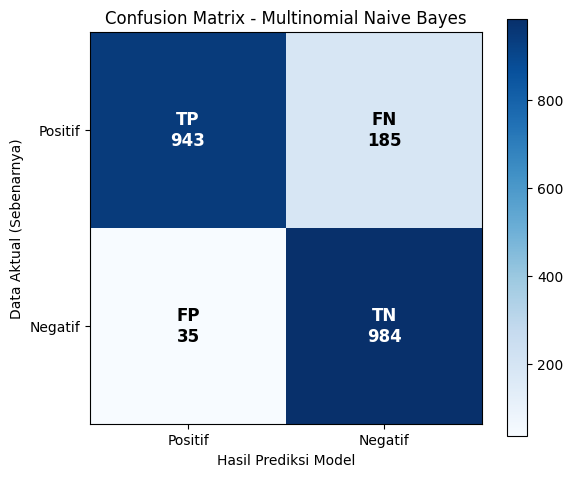

In [4]:
# Menghitung Confusion Matrix dengan urutan label ['positif', 'negatif'] sesuai Tabel 3.5 Proposal Skripsi
cm_mnb = confusion_matrix(y_test, y_pred_mnb, labels=['positif', 'negatif'])

# Mengekstrak nilai TP, FN, FP, TN sesuai posisi Tabel 3.5
TP = cm_mnb[0, 0] # Aktual Positif, Prediksi Positif
FN = cm_mnb[0, 1] # Aktual Positif, Prediksi Negatif
FP = cm_mnb[1, 0] # Aktual Negatif, Prediksi Positif
TN = cm_mnb[1, 1] # Aktual Negatif, Prediksi Negatif

print("=== RINCIAN CONFUSION MATRIX MULTINOMIAL NAIVE BAYES ===")
print(f"- True Positive  (TP) : {TP} (Aktual Positif -> Prediksi Positif)")
print(f"- True Negative  (TN) : {TN} (Aktual Negatif -> Prediksi Negatif)")
print(f"- False Positive (FP) : {FP} (Aktual Negatif -> Prediksi Positif)")
print(f"- False Negative (FN) : {FN} (Aktual Positif -> Prediksi Negatif)")

# Menampilkan Confusion Matrix dalam bentuk Tabel DataFrame (sesuai Tabel 3.5 Proposal)
df_cm_mnb = pd.DataFrame(
    cm_mnb,
    index=['Aktual: Positif', 'Aktual: Negatif'],
    columns=['Prediksi: Positif', 'Prediksi: Negatif']
)
display(df_cm_mnb)

# Visualisasi Heatmap Confusion Matrix menggunakan Matplotlib (Siap disimpan untuk Bab IV Skripsi)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_mnb, interpolation='nearest', cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(cm_mnb.shape[1]),
    yticks=np.arange(cm_mnb.shape[0]),
    xticklabels=['Positif', 'Negatif'],
    yticklabels=['Positif', 'Negatif'],
    title='Confusion Matrix - Multinomial Naive Bayes',
    ylabel='Data Aktual (Sebenarnya)',
    xlabel='Hasil Prediksi Model'
)

# Menambahkan teks angka dan label (TP, FN, FP, TN) di tengah kotak
label_kotak = [['TP', 'FN'], ['FP', 'TN']]
thresh = cm_mnb.max() / 2.0
for i in range(cm_mnb.shape[0]):
    for j in range(cm_mnb.shape[1]):
        ax.text(
            j, i,
            f"{label_kotak[i][j]}\n{cm_mnb[i, j]}",
            ha="center", va="center",
            color="white" if cm_mnb[i, j] > thresh else "black",
            fontsize=12, fontweight='bold'
        )

plt.tight_layout()
plt.show()

### 4.2 Perhitungan Accuracy, Precision, Recall, dan F1-Score

**Rumus Sesuai Subbab 3.12 Proposal Skripsi:**
1. **Accuracy** $= \frac{TP + TN}{TP + TN + FP + FN}$ $\rightarrow$ Persentase total tebakan yang benar dari seluruh data uji.
2. **Precision** $= \frac{TP}{TP + FP}$ $\rightarrow$ Ketepatan model saat memprediksi kelas positif.
3. **Recall** $= \frac{TP}{TP + FN}$ $\rightarrow$ Kemampuan model menemukan kembali seluruh data yang benar-benar positif.
4. **F1-Score** $= \frac{2 \times Precision \times Recall}{Precision + Recall}$ $\rightarrow$ Rata-rata harmonik yang menyeimbangkan *Precision* dan *Recall*.

In [5]:
# Menghitung metrik evaluasi menggunakan scikit-learn (dengan kelas 'positif' sebagai pos_label sesuai rumus TP/TN/FP/FN)
acc_mnb = accuracy_score(y_test, y_pred_mnb)
prec_mnb = precision_score(y_test, y_pred_mnb, pos_label='positif')
rec_mnb = recall_score(y_test, y_pred_mnb, pos_label='positif')
f1_mnb = f1_score(y_test, y_pred_mnb, pos_label='positif')

# Menghitung juga rata-rata tertimbang (weighted average) untuk keseluruhan kelas
prec_weighted_mnb = precision_score(y_test, y_pred_mnb, average='weighted')
rec_weighted_mnb = recall_score(y_test, y_pred_mnb, average='weighted')
f1_weighted_mnb = f1_score(y_test, y_pred_mnb, average='weighted')

print("=== HASIL EVALUASI KINERJA MULTINOMIAL NAIVE BAYES ===")
print(f"1. Accuracy  : {acc_mnb:.4f} ({acc_mnb * 100:.2f}%)")
print(f"2. Precision : {prec_mnb:.4f} ({prec_mnb * 100:.2f}%)")
print(f"3. Recall    : {rec_mnb:.4f} ({rec_mnb * 100:.2f}%)")
print(f"4. F1-Score  : {f1_mnb:.4f} ({f1_mnb * 100:.2f}%)")

print("\n=== LAPORAN KLASIFIKASI LENGKAP (PER KELAS SENTIMEN) ===")
print(classification_report(y_test, y_pred_mnb, target_names=['negatif', 'positif'], digits=4))

# Tabel ringkasan metrik untuk disalin ke Bab IV Skripsi
df_ringkasan_mnb = pd.DataFrame({
    'Metode': ['Multinomial Naive Bayes (alpha=1.0)'],
    'Accuracy (%)': [round(acc_mnb * 100, 2)],
    'Precision (%)': [round(prec_mnb * 100, 2)],
    'Recall (%)': [round(rec_mnb * 100, 2)],
    'F1-Score (%)': [round(f1_mnb * 100, 2)],
    'TP': [TP],
    'TN': [TN],
    'FP': [FP],
    'FN': [FN]
})
df_ringkasan_mnb

=== HASIL EVALUASI KINERJA MULTINOMIAL NAIVE BAYES ===
1. Accuracy  : 0.8975 (89.75%)
2. Precision : 0.9642 (96.42%)
3. Recall    : 0.8360 (83.60%)
4. F1-Score  : 0.8955 (89.55%)

=== LAPORAN KLASIFIKASI LENGKAP (PER KELAS SENTIMEN) ===
              precision    recall  f1-score   support

     negatif     0.8417    0.9657    0.8995      1019
     positif     0.9642    0.8360    0.8955      1128

    accuracy                         0.8975      2147
   macro avg     0.9030    0.9008    0.8975      2147
weighted avg     0.9061    0.8975    0.8974      2147



,Metode,Accuracy (%),Precision (%),Recall (%),F1-Score (%),TP,TN,FP,FN
0,Multinomial Naive Bayes (alpha=1.0),89.75,96.42,83.6,89.55,943,984,35,185


---
## 5. Menyimpan Model & Hasil Evaluasi Multinomial Naive Bayes

Kita simpan model serta seluruh nilai metrik evaluasinya ke folder `../data/` agar nanti pada tahap **Perbandingan Kinerja Metode (Multinomial Naive Bayes vs KNN)** kita tidak perlu melatih ulang dari awal.

In [8]:
# 1. Simpan model Multinomial Naive Bayes yang sudah dilatih
joblib.dump(mnb_model, "../data/model-naive-bayes/model_naive_bayes.pkl")

# 2. Simpan tabel hasil prediksi pada Data Uji ke CSV
df_hasil_uji_mnb.to_csv("../data/model-naive-bayes/hasil_prediksi_naive_bayes.csv", index=False)

# 3. Simpan paket metrik evaluasi MNB untuk dibandingkan dengan KNN nanti
evaluasi_mnb = {
    'nama_metode': 'Multinomial Naive Bayes',
    'accuracy': acc_mnb,
    'precision': prec_mnb,
    'recall': rec_mnb,
    'f1_score': f1_mnb,
    'precision_weighted': prec_weighted_mnb,
    'recall_weighted': rec_weighted_mnb,
    'f1_weighted': f1_weighted_mnb,
    'confusion_matrix': cm_mnb,
    'TP': int(TP),
    'TN': int(TN),
    'FP': int(FP),
    'FN': int(FN),
    'y_pred': y_pred_mnb
}
joblib.dump(evaluasi_mnb, "../data/model-naive-bayes/evaluasi_naive_bayes.pkl")

print("=== PENYIMPANAN BERHASIL ===")
print("1. Model Multinomial NB       -> ../data/model-naive-bayes/model_naive_bayes.pkl")
print("2. Tabel Hasil Prediksi (CSV) -> ../data/model-naive-bayes/hasil_prediksi_naive_bayes.csv")
print("3. Ringkasan Evaluasi MNB     -> ../data/model-naive-bayes/evaluasi_naive_bayes.pkl")

=== PENYIMPANAN BERHASIL ===
1. Model Multinomial NB       -> ../data/model-naive-bayes/model_naive_bayes.pkl
2. Tabel Hasil Prediksi (CSV) -> ../data/model-naive-bayes/hasil_prediksi_naive_bayes.csv
3. Ringkasan Evaluasi MNB     -> ../data/model-naive-bayes/evaluasi_naive_bayes.pkl
